<b>ML Experiment 4: Implementation of Regression Models with Regularization</b><br><br><b>Aim:</b> Use RidgeCV, LassoCV, and ElasticNetCV to control high-degree polynomial overfitting and perform cross-validated regularization on the Diabetes dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
rng = np.random.default_rng(409)
x_curve = np.linspace(-2.8, 2.8, 75).reshape(-1, 1)
y_curve = np.cos(1.3 * x_curve.ravel()) + 0.4 * (x_curve.ravel() ** 2) + rng.normal(0.0, 0.32, 75)
xc_tr, xc_te, yc_tr, yc_te = train_test_split(x_curve, y_curve, test_size=0.3, random_state=41)

poly_ols = make_pipeline(PolynomialFeatures(9), StandardScaler(), LinearRegression()).fit(xc_tr, yc_tr)
poly_ridge = make_pipeline(
    PolynomialFeatures(9), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 2, 25))
).fit(xc_tr, yc_tr)
poly_lasso = make_pipeline(
    PolynomialFeatures(9), StandardScaler(), LassoCV(alphas=np.logspace(-3, 1, 25), max_iter=15000, random_state=41)
).fit(xc_tr, yc_tr)

print("Degree-9 Polynomial Regularization Check:")
for label, pipe in [("OLS", poly_ols), ("RidgeCV", poly_ridge), ("LassoCV", poly_lasso)]:
    tr_err = mean_squared_error(yc_tr, pipe.predict(xc_tr))
    te_err = mean_squared_error(yc_te, pipe.predict(xc_te))
    print(f"{label:8s} | Train MSE: {tr_err:.4f} | Test MSE: {te_err:.4f}")

diabetes = load_diabetes(as_frame=True)
x_tr, x_te, y_tr, y_te = train_test_split(diabetes.data, diabetes.target, test_size=0.22, random_state=53)

Degree-9 Polynomial Regularization Check:
OLS      | Train MSE: 0.0657 | Test MSE: 0.0818
RidgeCV  | Train MSE: 0.0727 | Test MSE: 0.1023
LassoCV  | Train MSE: 0.0776 | Test MSE: 0.1159


In [3]:
scaler = StandardScaler()
x_tr_scaled = scaler.fit_transform(x_tr)
x_te_scaled = scaler.transform(x_te)

alpha_grid = np.logspace(-3, 2.5, 45)
ols_model = LinearRegression().fit(x_tr_scaled, y_tr)
ridge_cv = RidgeCV(alphas=alpha_grid, cv=5).fit(x_tr_scaled, y_tr)
lasso_cv = LassoCV(alphas=alpha_grid, cv=5, max_iter=15000, random_state=53).fit(x_tr_scaled, y_tr)
enet_cv = ElasticNetCV(alphas=alpha_grid, l1_ratio=[0.2, 0.5, 0.8], cv=5, max_iter=15000, random_state=53).fit(
    x_tr_scaled, y_tr
)

summary_rows = []
for name, est in [
    ("OLS", ols_model),
    (f"RidgeCV (a={ridge_cv.alpha_:.2f})", ridge_cv),
    (f"LassoCV (a={lasso_cv.alpha_:.2f})", lasso_cv),
    (f"ElasticNetCV (a={enet_cv.alpha_:.2f})", enet_cv),
]:
    preds = est.predict(x_te_scaled)
    summary_rows.append({
        "Estimator": name,
        "Test_MSE": round(mean_squared_error(y_te, preds), 2),
        "Test_R2": round(r2_score(y_te, preds), 4),
        "Active_Features": int(np.sum(np.abs(est.coef_) > 1e-4)),
    })

print("\nCross-Validated Regularization on Diabetes Data:")
print(pd.DataFrame(summary_rows).to_string(index=False))


Cross-Validated Regularization on Diabetes Data:
            Estimator  Test_MSE  Test_R2  Active_Features
                  OLS   2925.09   0.5072               10
    RidgeCV (a=42.17)   2881.03   0.5147               10
     LassoCV (a=0.00)   2924.63   0.5073               10
ElasticNetCV (a=0.18)   2888.55   0.5134               10


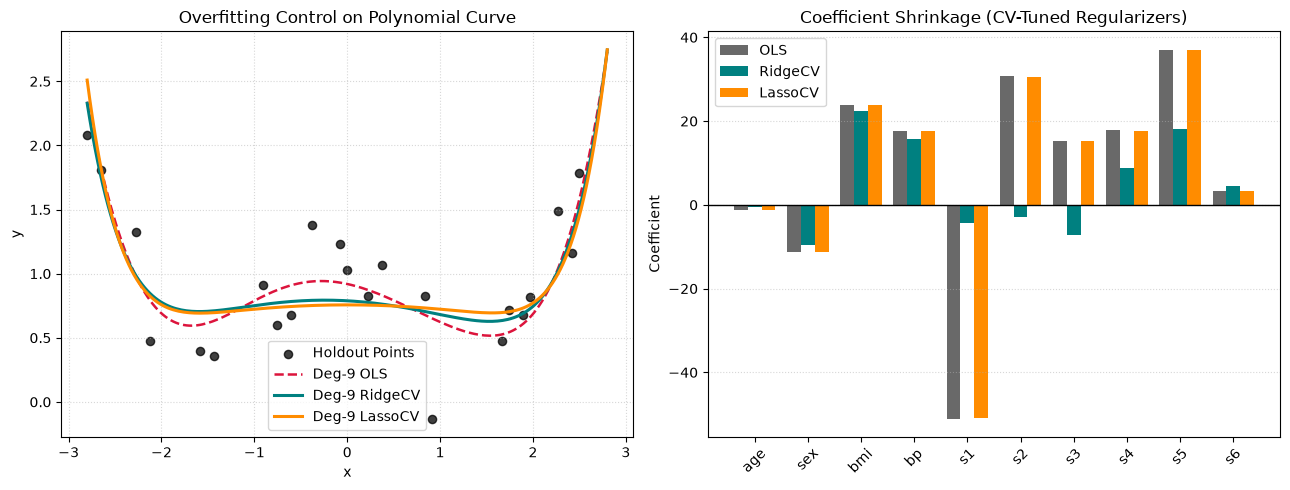

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sort_idx = np.argsort(xc_te.ravel())
x_plot = np.linspace(-2.8, 2.8, 200).reshape(-1, 1)
ax[0].scatter(xc_te, yc_te, color="black", s=35, alpha=0.75, label="Holdout Points")
ax[0].plot(x_plot, poly_ols.predict(x_plot), color="crimson", linestyle="--", linewidth=1.8, label="Deg-9 OLS")
ax[0].plot(x_plot, poly_ridge.predict(x_plot), color="teal", linewidth=2.2, label="Deg-9 RidgeCV")
ax[0].plot(x_plot, poly_lasso.predict(x_plot), color="darkorange", linewidth=2.2, label="Deg-9 LassoCV")
ax[0].set_title("Overfitting Control on Polynomial Curve")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].legend()
ax[0].grid(True, linestyle=":", alpha=0.5)

pos = np.arange(len(diabetes.feature_names))
w = 0.26
ax[1].bar(pos - w, ols_model.coef_, width=w, color="dimgray", label="OLS")
ax[1].bar(pos, ridge_cv.coef_, width=w, color="teal", label="RidgeCV")
ax[1].bar(pos + w, lasso_cv.coef_, width=w, color="darkorange", label="LassoCV")
ax[1].set_xticks(pos)
ax[1].set_xticklabels(diabetes.feature_names, rotation=45)
ax[1].axhline(0.0, color="black", linewidth=1)
ax[1].set_title("Coefficient Shrinkage (CV-Tuned Regularizers)")
ax[1].set_ylabel("Coefficient")
ax[1].legend()
ax[1].grid(True, axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

<b>Observation:</b> Cross-validated RidgeCV and LassoCV reduce generalization MSE over unregularized OLS while LassoCV eliminates redundant coefficients.